# Graph Analysis & Link Prediction — Enron Email Network

Πλήρης ανάλυση γράφου και σύγκριση μεθόδων πρόβλεψης συνδέσμων.

## Step 0: Import Libraries & Load Data

In [1]:
import networkx as nx
import random
import collections
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, roc_curve, auc,
                             precision_score, recall_score, f1_score)

# Αφαιρούμε self-loops και φορτώνουμε ως απλό μη κατευθυνόμενο γράφο
G = nx.read_edgelist("Email-Enron.txt", nodetype=int)
G.remove_edges_from(nx.selfloop_edges(G))

print(f"Nodes: {G.number_of_nodes()}")
print(f"Edges: {G.number_of_edges()}")

Nodes: 36692
Edges: 183831


## Step 1: Exploratory Analysis — Connected Components

In [2]:
# Εντοπισμός συνεκτικών συνιστωσών
connected_components = list(nx.connected_components(G))
print(f"Total components: {len(connected_components)}")

# Γιγαντιαία συνιστώσα
giant_component = max(connected_components, key=len)
print(f"Giant Component: {len(giant_component)} nodes "
      f"({len(giant_component)/G.number_of_nodes()*100:.2f}% of network)")

Total components: 1065
Giant Component: 33696 nodes (91.83% of network)


## Step 2: Centrality Measures

In [11]:
# --- Degree Centrality ---
# Ποιος έχει τις περισσότερες άμεσες επαφές
deg_centrality = nx.degree_centrality(G)
top_5_deg = sorted(deg_centrality, key=deg_centrality.get, reverse=True)[:5]
print(f"Degree Centrality (Top 5):      {top_5_deg}")

# --- Eigenvector Centrality ---
# Ποιος είναι συνδεδεμένος με σημαντικούς κόμβους
eig_centrality = nx.eigenvector_centrality(G, max_iter=1000)
top_5_eig = sorted(eig_centrality, key=eig_centrality.get, reverse=True)[:5]
print(f"Eigenvector Centrality (Top 5): {top_5_eig}")

# --- Betweenness Centrality ---
# Ποιος λειτουργεί ως «γέφυρα» πληροφορίας (sampling για ταχύτητα)
bet_centrality = nx.betweenness_centrality(G, k=100, seed=42)
top_5_bet = sorted(bet_centrality, key=bet_centrality.get, reverse=True)[:5]
print(f"Betweenness Centrality (Top 5): {top_5_bet}")

# --- Closeness Centrality ---
# Ποιος φτάνει γρηγορότερα σε όλους τους άλλους
close_centrality = nx.closeness_centrality(G)
top_5_close = sorted(close_centrality, key=close_centrality.get, reverse=True)[:5]
print(f"Closeness Centrality (Top 5):   {top_5_close}")

Degree Centrality (Top 5):      [5038, 273, 458, 140, 1028]
Eigenvector Centrality (Top 5): [136, 195, 76, 370, 1028]
Betweenness Centrality (Top 5): [140, 5038, 566, 823, 273]
Closeness Centrality (Top 5):   [136, 76, 46, 140, 370]


## Step 3: Clustering, Triangles & Transitivity

In [6]:
# Μέσος συντελεστής συσταδοποίησης (προσεγγιστικά για ταχύτητα)
clustering_approx = nx.approximation.average_clustering(G, trials=5000, seed=42)
print(f"Average Clustering Coefficient: {clustering_approx:.4f}")

# Αριθμός τριγώνων
triangles_dict = nx.triangles(G)
total_triangles = sum(triangles_dict.values()) // 3
print(f"Total Triangles:                {total_triangles}")

# Μεταβατικότητα
transitivity_score = nx.transitivity(G)
print(f"Transitivity:                   {transitivity_score:.4f}")

Average Clustering Coefficient: 0.5042
Total Triangles:                727044
Transitivity:                   0.0853


## Step 4: Degree Distribution Plots

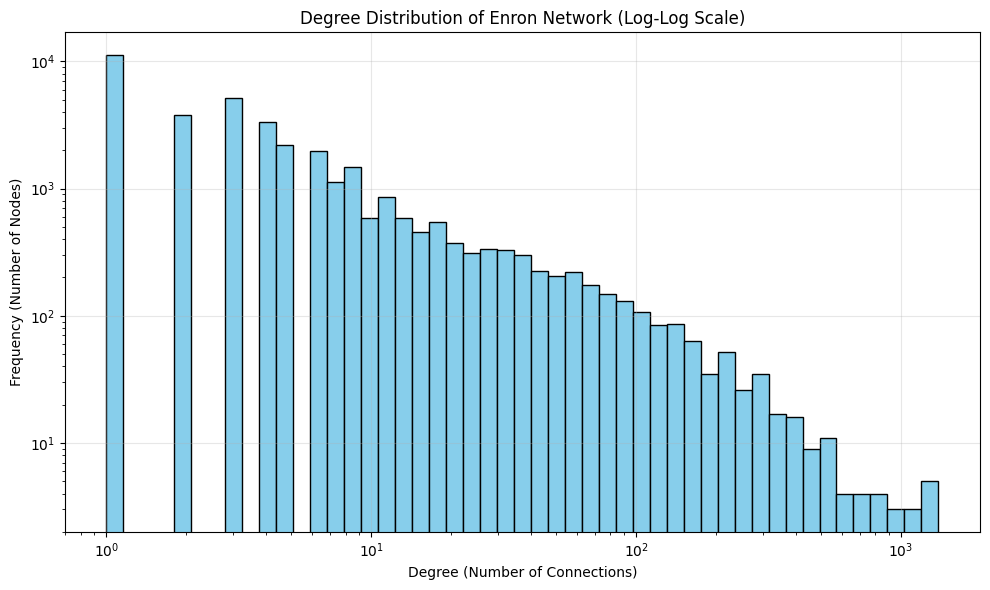

In [7]:
degrees = [degree for node, degree in G.degree()]

# --- Plot 1: Histogram (Log-Log) ---
plt.figure(figsize=(10, 6))
plt.hist(degrees,
         bins=np.logspace(np.log10(1), np.log10(max(degrees)), 50),
         color='skyblue', edgecolor='black')
plt.xscale('log')
plt.yscale('log')
plt.title('Degree Distribution of Enron Network (Log-Log Scale)')
plt.xlabel('Degree (Number of Connections)')
plt.ylabel('Frequency (Number of Nodes)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

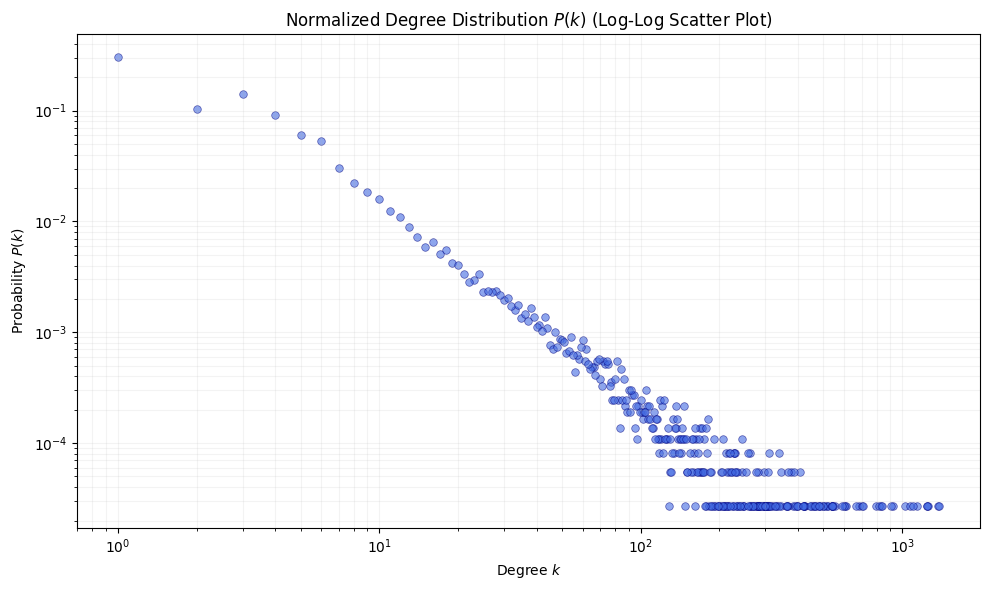

In [8]:
# --- Plot 2: Normalized P(k) Scatter (Log-Log) ---
degree_counts = collections.Counter(degrees)
total_nodes = G.number_of_nodes()
degrees_list = list(degree_counts.keys())
probabilities = [count / total_nodes for count in degree_counts.values()]

plt.figure(figsize=(10, 6))
plt.scatter(degrees_list, probabilities,
            color='royalblue', alpha=0.6, s=30,
            edgecolor='navy', linewidth=0.5)
plt.xscale('log')
plt.yscale('log')
plt.title('Normalized Degree Distribution $P(k)$ (Log-Log Scatter Plot)')
plt.xlabel('Degree $k$')
plt.ylabel('Probability $P(k)$')
plt.grid(True, which="both", ls="-", alpha=0.15)
plt.tight_layout()
plt.show()

## Step 5: Visualizations — Ego Graph 

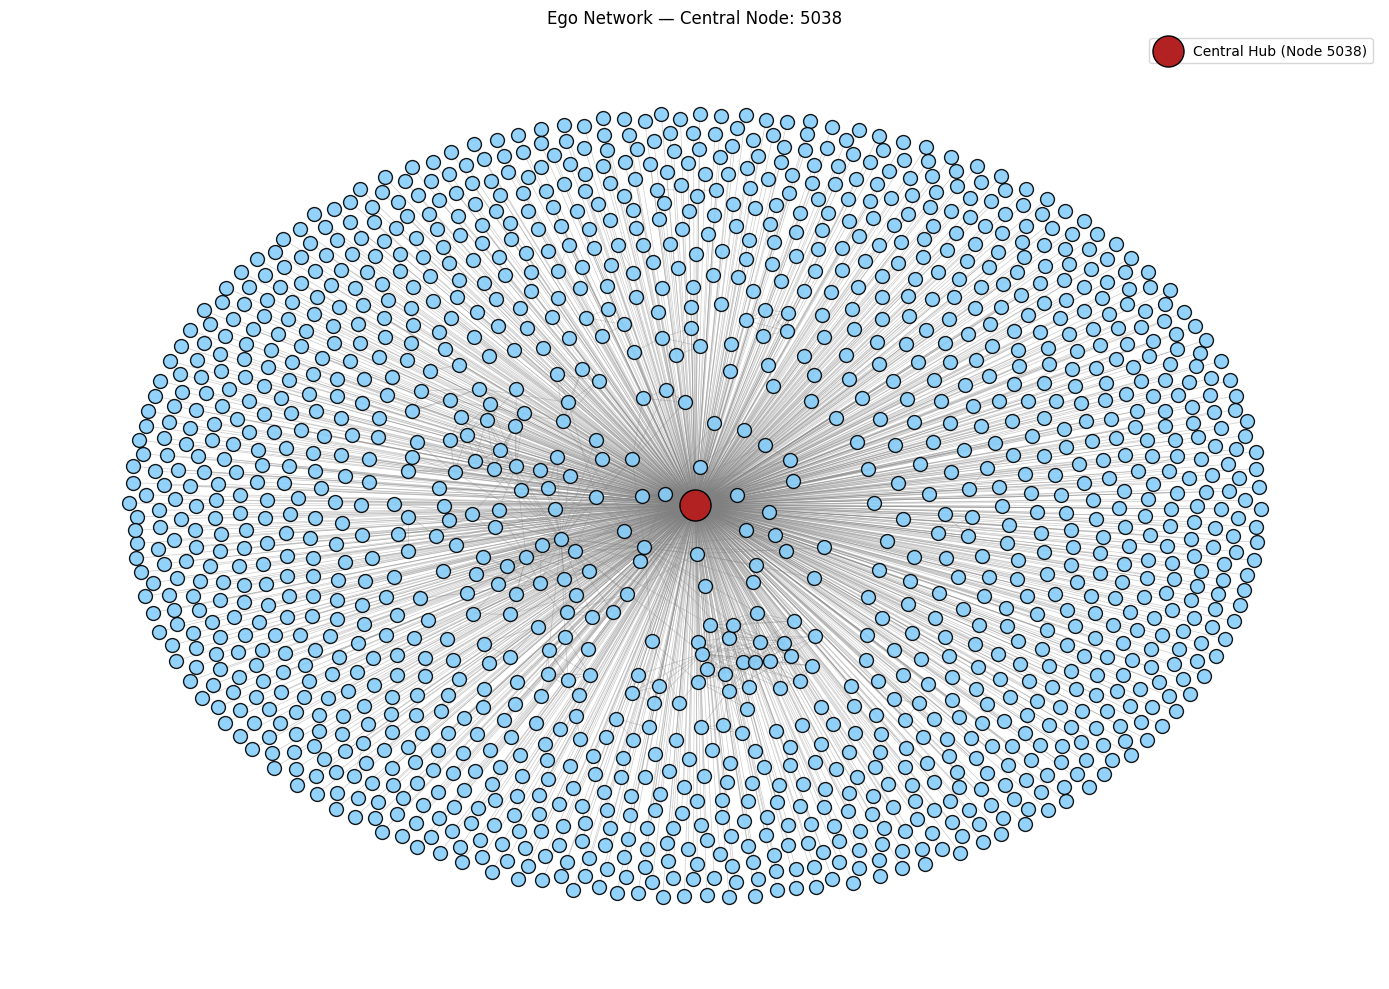

In [6]:
# --- Ego Graph: Τοπική γειτονιά του κόμβου με το μεγαλύτερο degree ---
degrees_dict = dict(G.degree())
top_node = max(degrees_dict, key=degrees_dict.get)

ego_net = nx.ego_graph(G, n=top_node, radius=1)
pos = nx.spring_layout(ego_net, k=0.25, iterations=100, seed=42)

plt.figure(figsize=(14, 10))
nx.draw_networkx_nodes(ego_net, pos, node_size=100,
                       node_color='lightskyblue', edgecolors='black', alpha=0.9)
nx.draw_networkx_edges(ego_net, pos, width=0.5, edge_color='gray', alpha=0.4)
nx.draw_networkx_nodes(ego_net, pos, nodelist=[top_node],
                       node_size=500, node_color='firebrick',
                       edgecolors='black', alpha=1,
                       label=f'Central Hub (Node {top_node})')
plt.title(f'Ego Network — Central Node: {top_node}')
plt.axis('off')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

## Step 6: Data Preparation for Link Prediction

In [9]:
# --- 6.1 Positive Sampling: Κρύβουμε 10% των ακμών για testing ---
G_train = G.copy()
all_edges = list(G.edges())
num_test_edges = int(0.10 * len(all_edges))

random.seed(42)
random.shuffle(all_edges)

test_edges_pos  = all_edges[:num_test_edges]    # 10% → test positives
train_edges_all = all_edges[num_test_edges:]    # 90% → training edges

# Αφαιρούμε τα test edges από τον training graph
G_train.remove_edges_from(test_edges_pos)

print(f"Positive test edges:             {len(test_edges_pos)}")
print(f"Remaining edges in G_train:      {G_train.number_of_edges()}")

Positive test edges:             18383
Remaining edges in G_train:      165448


In [10]:
# --- 6.2 Negative Sampling: Ζεύγη κόμβων χωρίς σύνδεση ---

random.seed(42) 

test_edges_neg = []
train_edges_neg = []
nodes = list(G.nodes())


# Test negatives
while len(test_edges_neg) < num_test_edges:
    u, v = random.sample(nodes, 2)
    if not G.has_edge(u, v) and u != v:
        test_edges_neg.append((u, v))

# Train negatives (ίδιος αριθμός με train positives για balanced dataset)
num_train_edges = len(train_edges_all)
test_neg_set = set(tuple(sorted(e)) for e in test_edges_neg)
while len(train_edges_neg) < num_train_edges:
    u, v = random.sample(nodes, 2)
    if not G.has_edge(u, v) and u != v and tuple(sorted((u,v))) not in test_neg_set:
        train_edges_neg.append((u, v))

print(f"Negative test edges:             {len(test_edges_neg)}")
print(f"Negative train edges:            {len(train_edges_neg)}")

Negative test edges:             18383
Negative train edges:            165448


In [11]:
# --- 6.3 Αποθήκευση G_train ως .edg για το PecanPy ---
# (Απαιτείται από τον αλγόριθμο Node2Vec αν χρειαστεί επανεκπαίδευση)

with open("temp_train.edg", "w") as f:
    for u, v in G_train.edges():
        line = f"{u} {v}\n"
        if line.strip():  # αγνοεί κενές γραμμές
            f.write(line)
print("temp_train.edg saved successfully.")

temp_train.edg saved successfully.


In [12]:
# --- 6.4 Αποθήκευση test edges για συνέπεια αποτελεσμάτων ---
np.save("test_edges_pos.npy", np.array(test_edges_pos))
np.save("test_edges_neg.npy", np.array(test_edges_neg))
print("test_edges_pos.npy και test_edges_neg.npy αποθηκεύτηκαν.")

test_edges_pos.npy και test_edges_neg.npy αποθηκεύτηκαν.


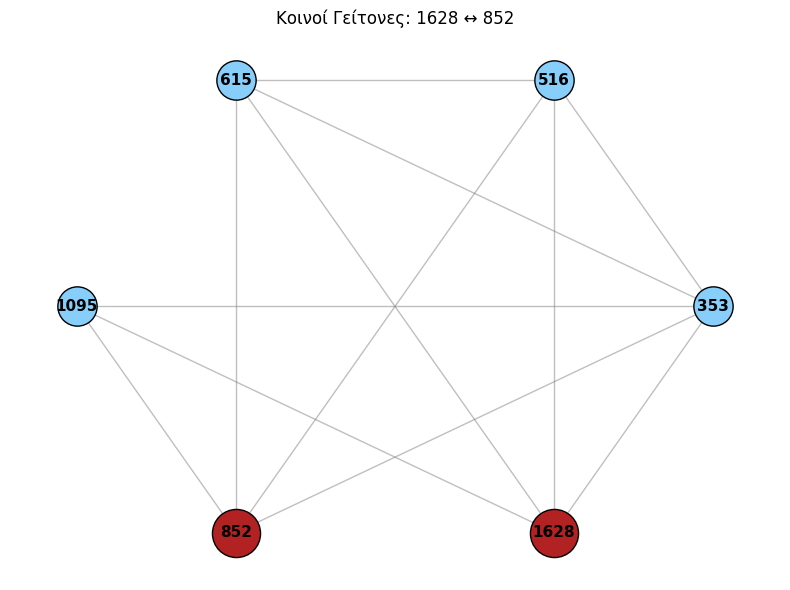

In [13]:
# Visualization: Κοινοί γείτονες για ένα ζεύγος test
node_u, node_v = test_edges_pos[0]
common = list(nx.common_neighbors(G_train, node_u, node_v))[:4]

nodes_to_show = [node_u, node_v] + common
subgraph = G_train.subgraph(nodes_to_show)
pos = nx.circular_layout(subgraph)

plt.figure(figsize=(8, 6))
nx.draw_networkx_nodes(subgraph, pos, nodelist=common,
                       node_color='lightskyblue', node_size=800, edgecolors='black')
nx.draw_networkx_nodes(subgraph, pos, nodelist=[node_u, node_v],
                       node_color='firebrick', node_size=1200, edgecolors='black')
nx.draw_networkx_edges(subgraph, pos, edge_color='gray', alpha=0.5)
nx.draw_networkx_labels(subgraph, pos, font_size=11, font_weight='bold')
plt.title(f'Κοινοί Γείτονες: {node_u} ↔ {node_v}')
plt.axis('off')
plt.tight_layout()
plt.show()

## Step 7: Classical Methods - Jaccard & Adamic-Adar

In [14]:
# Φορτώνουμε τα αποθηκευμένα test edges
test_edges_pos = [tuple(e) for e in np.load("test_edges_pos.npy")]
test_edges_neg = [tuple(e) for e in np.load("test_edges_neg.npy")]

# Ενώνουμε test edges και δημιουργούμε labels
all_test_edges = test_edges_pos + test_edges_neg
y_test_true = np.array([1] * len(test_edges_pos) + [0] * len(test_edges_neg))

# --- Jaccard Coefficient ---
jaccard_scores = [p for u, v, p in nx.jaccard_coefficient(G_train, all_test_edges)]

# --- Adamic-Adar Index ---
adar_scores = [p for u, v, p in nx.adamic_adar_index(G_train, all_test_edges)]

auc_jaccard = roc_auc_score(y_test_true, jaccard_scores)
auc_adamic  = roc_auc_score(y_test_true, adar_scores)
print(f"Jaccard AUC:     {auc_jaccard:.4f}")
print(f"Adamic-Adar AUC: {auc_adamic:.4f}")

Jaccard AUC:     0.9488
Adamic-Adar AUC: 0.9546


## Step 8a: Embedding Generation (Node2Vec — PecanPy)

> **ΠΡΟΣΟΧΗ:** Αυτό το cell παράγει τα embeddings από την αρχή.
> Διαρκεί **~78 λεπτά** και απαιτεί το `temp_train.edg`.
> 
> **Υπάρχουν ήδη τα `.npy` αρχεία, δεν απαιτείται εκτέλεση — κατευθείαν Step 8b.**

In [ ]:
# ============================================================
# EMBEDDING GENERATION — Node2Vec Grid Search (p, q)
 
# ============================================================

import time
import os
import random
import numpy as np
from pecanpy import pecanpy as node2vec
from gensim.models import Word2Vec

# --- Σταθερές παράμετροι ---
np.random.seed(42)
random.seed(42)

cores      = max(1, os.cpu_count() - 1)
NUM_WALKS  = 40
WALK_LENGTH = 80
VECTOR_DIM  = 128
WINDOW_SIZE = 10
NUM_EPOCHS  = 5

# --- Στρατηγικές Grid Search ---
experiments = [
    {"p": 0.5, "q": 2.0, "name": "BFS"},
    {"p": 1.0, "q": 0.5, "name": "DFS"},
    {"p": 1.0, "q": 1.0, "name": "DeepWalk"},
    {"p": 0.1, "q": 0.1, "name": "HighExploration"}
]

# --- Hadamard edge features ---
def get_edge_features(edge_list, model):
    features = []
    for u, v in edge_list:
        str_u, str_v = str(u), str(v)
        if str_u in model.wv and str_v in model.wv:
            features.append(model.wv[str_u] * model.wv[str_v])
        else:
            features.append(np.zeros(model.vector_size))
    return np.array(features)

# --- Labels (κοινά για όλα τα experiments) ---
y_train = np.array([1]*len(train_edges_all) + [0]*len(train_edges_neg))
y_test  = np.array([1]*len(test_edges_pos)  + [0]*len(test_edges_neg))

print(f"Starting Embedding Generation for {len(experiments)} experiments...\n")
total_start = time.time()

for exp in experiments:
    exp_name = exp['name']
    print(f"-> Running experiment: {exp_name} (p={exp['p']}, q={exp['q']})")
    start_time = time.time()

    # 1. Random Walks
    g = node2vec.SparseOTF(p=exp["p"], q=exp["q"], workers=-1, verbose=False)
    g.read_edg("temp_train.edg", weighted=False, directed=False, delimiter=" ")
    walks = g.simulate_walks(num_walks=NUM_WALKS, walk_length=WALK_LENGTH)

    # 2. Word2Vec
    model = Word2Vec(walks, vector_size=VECTOR_DIM, window=WINDOW_SIZE,
                     min_count=1, sg=1, workers=cores, epochs=NUM_EPOCHS, seed=42)

    # 3. Feature Extraction (Hadamard)
    X_train = np.vstack([get_edge_features(train_edges_all, model),
                         get_edge_features(train_edges_neg,  model)])
    X_test  = np.vstack([get_edge_features(test_edges_pos,  model),
                         get_edge_features(test_edges_neg,  model)])

    # 4. Αποθήκευση
    np.save(f"X_train_{exp_name}.npy", X_train)
    np.save(f"X_test_{exp_name}.npy",  X_test)

    run_time = (time.time() - start_time) / 60
    print(f"   Successfully saved files for {exp_name} ({run_time:.1f} minutes)\n")

# Αποθήκευση labels
np.save("y_train.npy", y_train)
np.save("y_test.npy",  y_test)

total_time = (time.time() - total_start) / 60
print("=" * 60)
print(f"All experiments completed in {total_time:.1f} minutes!")

Starting Embedding Generation for 4 experiments...

-> Running experiment: BFS (p=0.5, q=2.0)
   Successfully saved files for BFS (19.4 minutes)

-> Running experiment: DFS (p=1.0, q=0.5)
   Successfully saved files for DFS (19.3 minutes)

-> Running experiment: DeepWalk (p=1.0, q=1.0)
   Successfully saved files for DeepWalk (19.7 minutes)

-> Running experiment: HighExploration (p=0.1, q=0.1)
   Successfully saved files for HighExploration (20.2 minutes)

All experiments completed in 78.6 minutes!


## Step 8b: Node2Vec - Grid Search (p, q)

Τα embeddings έχουν ήδη παραχθεί και αποθηκευτεί. Αυτό το cell φορτώνει τα αποθηκευμένα αρχεία και αξιολογεί κάθε στρατηγική.

In [15]:
experiments = ["BFS", "DFS", "DeepWalk", "HighExploration"]
exp_params  = {"BFS": (0.5, 2.0), "DFS": (1.0, 0.5),
               "DeepWalk": (1.0, 1.0), "HighExploration": (0.1, 0.1)}

y_train_labels = np.load("y_train.npy")
y_test_labels  = np.load("y_test.npy")

grid_results = []
print("Evaluating Grid Search experiments...\n")

for exp_name in experiments:
    X_train_exp = np.load(f"X_train_{exp_name}.npy")
    X_test_exp  = np.load(f"X_test_{exp_name}.npy")

    clf_exp = LogisticRegression(max_iter=1000, random_state=42)
    clf_exp.fit(X_train_exp, y_train_labels)

    y_pred = clf_exp.predict_proba(X_test_exp)[:, 1]
    auc_score = roc_auc_score(y_test_labels, y_pred)


    # Αποθήκευση probabilities 
    np.save(f"proba_{exp_name}.npy", y_pred)

    p, q = exp_params[exp_name]
    grid_results.append([exp_name, p, q, round(auc_score, 4)])
    print(f"  {exp_name:<20} p={p}, q={q}  →  AUC = {auc_score:.4f}")

df_grid = pd.DataFrame(grid_results, columns=["Strategy", "p", "q", "AUC Score"])
df_grid = df_grid.sort_values("AUC Score", ascending=False)
print("\n" + "="*50)
print(" NODE2VEC GRID SEARCH RESULTS".center(50))
print("="*50)
print(df_grid.to_string(index=False))

Evaluating Grid Search experiments...

  BFS                  p=0.5, q=2.0  →  AUC = 0.9205
  DFS                  p=1.0, q=0.5  →  AUC = 0.9193
  DeepWalk             p=1.0, q=1.0  →  AUC = 0.9192
  HighExploration      p=0.1, q=0.1  →  AUC = 0.9273

           NODE2VEC GRID SEARCH RESULTS           
       Strategy   p   q  AUC Score
HighExploration 0.1 0.1     0.9273
            BFS 0.5 2.0     0.9205
            DFS 1.0 0.5     0.9193
       DeepWalk 1.0 1.0     0.9192


## Step 8c: Statistical Test - DeLong's test

In [16]:
from scipy.stats import norm

scores_high = np.load("proba_HighExploration.npy")
scores_bfs  = np.load("proba_BFS.npy")
y_test_labels  = np.load("y_test.npy") 

def delong_test(y_true, y_pred1, y_pred2):
    """DeLong's test για σύγκριση δύο AUC."""
    n1 = np.sum(y_true == 1)  # positives
    n2 = np.sum(y_true == 0)  # negatives

    def auc_and_var(y_true, y_pred):
        pos = y_pred[y_true == 1]
        neg = y_pred[y_true == 0]
        auc = roc_auc_score(y_true, y_pred)
        
        v10 = np.array([np.mean(p > neg) for p in pos])
        v01 = np.array([np.mean(n < pos) for n in neg])
        
        var = (np.var(v10) / n1 + np.var(v01) / n2)
        return auc, var, v10, v01

    auc1, var1, v10_1, v01_1 = auc_and_var(y_true, y_pred1)
    auc2, var2, v10_2, v01_2 = auc_and_var(y_true, y_pred2)

    # Covariance μεταξύ των δύο
    cov = (np.cov(v10_1, v10_2)[0,1] / n1 + 
           np.cov(v01_1, v01_2)[0,1] / n2)

    diff = auc1 - auc2
    se = np.sqrt(var1 + var2 - 2*cov)
    z = diff / se
    p_value = 2 * (1 - norm.cdf(abs(z)))  # δίπλευρο

    return auc1, auc2, diff, z, p_value

auc_high, auc_bfs, diff, z, p = delong_test(
    y_test_labels, scores_high, scores_bfs
)

print(f"AUC HighExploration: {auc_high:.4f}")
print(f"AUC BFS:             {auc_bfs:.4f}")
print(f"Διαφορά:             {diff:.4f}")
print(f"Z-score:             {z:.4f}")
print(f"p-value:             {p:.4f}")

if p < 0.05:
    print("Στατιστικά σημαντική διαφορά (DeLong's test).")
else:
    print("Δεν υπάρχει στατιστικά σημαντική διαφορά.")

AUC HighExploration: 0.9273
AUC BFS:             0.9205
Διαφορά:             0.0067
Z-score:             5.8217
p-value:             0.0000
Στατιστικά σημαντική διαφορά (DeLong's test).


## Step 9: Final Node2Vec Model (Best Strategy: High Exploration)

In [22]:
# Φορτώνουμε τα embeddings της καλύτερης στρατηγικής (HighExploration)
X_train_best = np.load("X_train_HighExploration.npy")
X_test_best  = np.load("X_test_HighExploration.npy")

clf_final = LogisticRegression(max_iter=1000, random_state=42)
clf_final.fit(X_train_best, y_train_labels)

n2v_proba = clf_final.predict_proba(X_test_best)[:, 1]

# Βέλτιστο threshold μέσω ROC
fpr, tpr, thresholds = roc_curve(y_test_labels, n2v_proba)
best_thresh = thresholds[np.argmax(tpr - fpr)]
n2v_preds = (n2v_proba >= best_thresh).astype(int)

auc_n2v       = roc_auc_score(y_test_labels, n2v_proba)
precision_n2v = precision_score(y_test_labels, n2v_preds, zero_division=0)
recall_n2v    = recall_score(y_test_labels, n2v_preds, zero_division=0)
f1_n2v        = f1_score(y_test_labels, n2v_preds, zero_division=0)

print(f"Node2Vec (HighExploration) — AUC: {auc_n2v:.4f} | "
      f"Precision: {precision_n2v:.4f} | "
      f"Recall: {recall_n2v:.4f} | "
      f"F1: {f1_n2v:.4f}")

Node2Vec (HighExploration) — AUC: 0.9273 | Precision: 0.8553 | Recall: 0.8404 | F1: 0.8478


## Step 10: Overfitting Check

In [18]:
# Σύγκριση AUC στο train set vs test set
y_train_pred = clf_final.predict_proba(X_train_best)[:, 1]
train_auc = roc_auc_score(y_train_labels, y_train_pred)
test_auc  = roc_auc_score(y_test_labels,  n2v_proba)

diff = train_auc - test_auc
print(f"Train AUC: {train_auc:.4f}")
print(f"Test  AUC: {test_auc:.4f}")
print(f"Διαφορά:   {diff:.2%}")
if diff > 0.05:
    print("Ένδειξη υπερεκπαίδευσης (>5%) — απαιτείται αξιολόγηση.")
else:
    print("Δεν εντοπίστηκε υπερεκπαίδευση.")

Train AUC: 0.9733
Test  AUC: 0.9273
Διαφορά:   4.61%
Δεν εντοπίστηκε υπερεκπαίδευση.


## Step 11: Full Metrics Comparison Table

In [19]:
# Jaccard
fpr, tpr, thresholds = roc_curve(y_test_true, jaccard_scores)
preds_j = (np.array(jaccard_scores) >= thresholds[np.argmax(tpr - fpr)]).astype(int)

# Adamic-Adar
fpr, tpr, thresholds = roc_curve(y_test_true, adar_scores)
preds_a = (np.array(adar_scores) >= thresholds[np.argmax(tpr - fpr)]).astype(int)

# Node2Vec — βέλτιστο threshold όπως οι άλλοι
fpr, tpr, thresholds = roc_curve(y_test_labels, n2v_proba)
preds_n = (np.array(n2v_proba) >= thresholds[np.argmax(tpr - fpr)]).astype(int)

# Πίνακας σύγκρισης
comparison = [
    ["Jaccard",     roc_auc_score(y_test_true,   jaccard_scores), precision_score(y_test_true,   preds_j), recall_score(y_test_true,   preds_j), f1_score(y_test_true,   preds_j)],
    ["Adamic-Adar", roc_auc_score(y_test_true,   adar_scores),    precision_score(y_test_true,   preds_a), recall_score(y_test_true,   preds_a), f1_score(y_test_true,   preds_a)],
    ["Node2Vec+LR", roc_auc_score(y_test_labels, n2v_proba),      precision_score(y_test_labels, preds_n), recall_score(y_test_labels, preds_n), f1_score(y_test_labels, preds_n)],
]

df = pd.DataFrame(comparison, columns=["Μέθοδος", "AUC", "Precision", "Recall", "F1"])
print(df.to_string(index=False))

    Μέθοδος      AUC  Precision   Recall       F1
    Jaccard 0.948758   0.979325 0.912147 0.944543
Adamic-Adar 0.954611   0.981427 0.911222 0.945023
Node2Vec+LR 0.927260   0.855332 0.840396 0.847798


## Step 12: ROC Curve Comparison

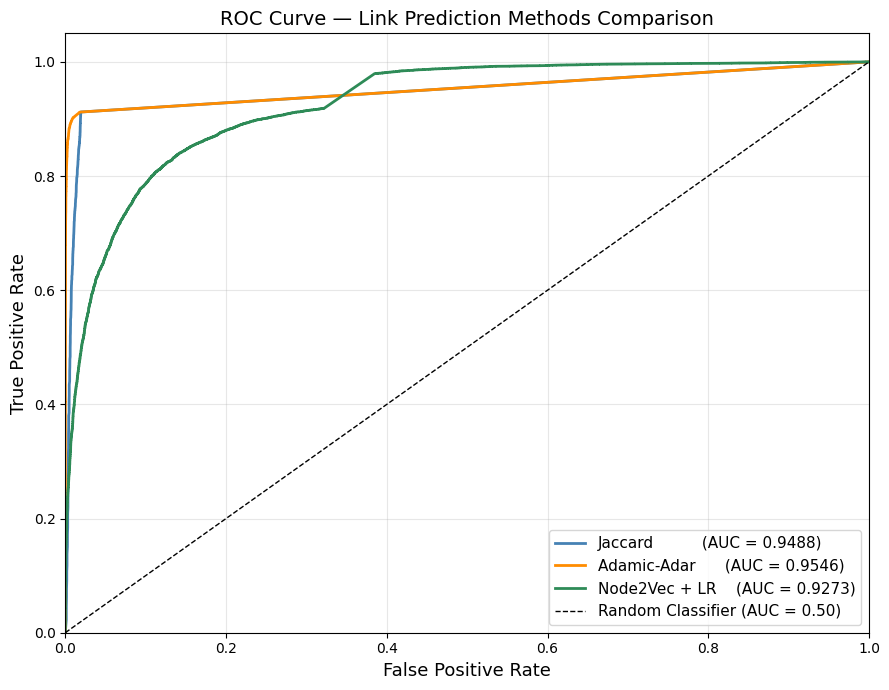

In [20]:
fpr_j, tpr_j, _ = roc_curve(y_test_true,   jaccard_scores)
fpr_a, tpr_a, _ = roc_curve(y_test_true,   adar_scores)
fpr_n, tpr_n, _ = roc_curve(y_test_labels, n2v_proba)

auc_j = roc_auc_score(y_test_true,   jaccard_scores)
auc_a = roc_auc_score(y_test_true,   adar_scores)
auc_n = roc_auc_score(y_test_labels, n2v_proba)

plt.figure(figsize=(9, 7))
plt.plot(fpr_j, tpr_j, color='steelblue',  lw=2, label=f'Jaccard          (AUC = {auc_j:.4f})')
plt.plot(fpr_a, tpr_a, color='darkorange', lw=2, label=f'Adamic-Adar      (AUC = {auc_a:.4f})')
plt.plot(fpr_n, tpr_n, color='seagreen',   lw=2, label=f'Node2Vec + LR    (AUC = {auc_n:.4f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Random Classifier (AUC = 0.50)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=13)
plt.ylabel('True Positive Rate', fontsize=13)
plt.title('ROC Curve — Link Prediction Methods Comparison', fontsize=14)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

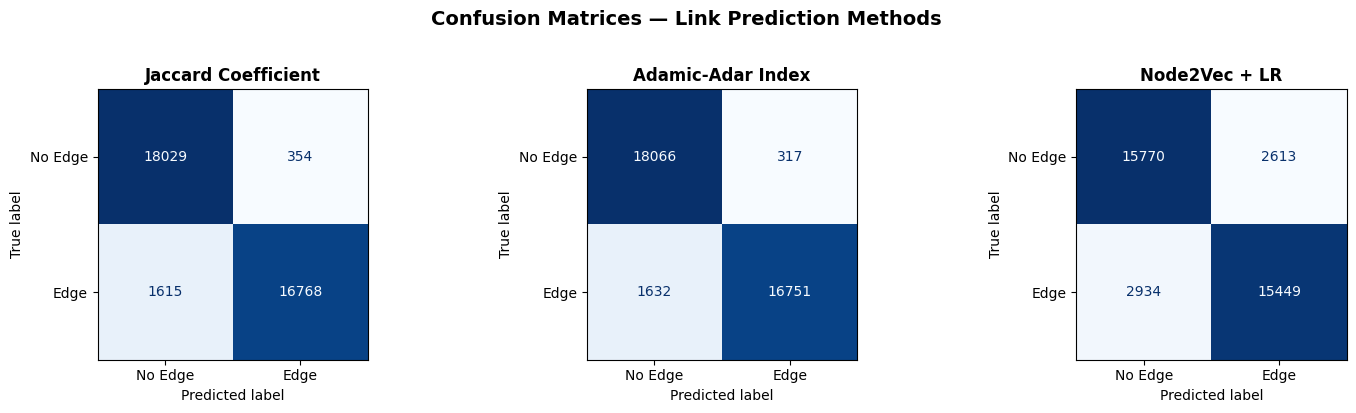

In [21]:
## Step 13: Confusion Matrices
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

methods = [
    ("Jaccard Coefficient", jaccard_scores, y_test_true,   None),
    ("Adamic-Adar Index",   adar_scores,    y_test_true,   None),
    ("Node2Vec + LR",       n2v_proba,      y_test_labels, None)
]

for ax, (name, scores, y_true, thresh) in zip(axes, methods):
    scores_arr = np.array(scores)
    if thresh is None:
        fpr, tpr, thresholds = roc_curve(y_true, scores_arr)
        best_thresh = thresholds[np.argmax(tpr - fpr)]
        preds = (scores_arr >= best_thresh).astype(int)
    else:
        preds = (scores_arr >= thresh).astype(int)

    cm = confusion_matrix(y_true, preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                  display_labels=["No Edge", "Edge"])
    disp.plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name, fontsize=12, fontweight='bold')

plt.suptitle("Confusion Matrices — Link Prediction Methods",
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()